# Zero-shot single-slide embedding visualization & clustering pipeline

Aim is to demonstrate that pretrained scGPT-spatial embeddings, without any fine-tuning, capture biologically meaningful structure in a single spatial transcriptomics slide.

### Setup and imports

Loads scanpy/scGPT-spatial dependencies and adds the local scgpt_spatial package to the path. 

np.float = float and np.int = int patch deprecated NumPy aliases that older dependencies (like scib) still rely on. It's safe to keep for compatibility with NumPy ≥1.24, but should be removed once the dependency chain is updated.

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import mode
import scanpy as sc
import warnings
from matplotlib import pyplot as plt

from typing import Dict, Optional, Union
import torch
from tqdm import tqdm
from scipy.sparse import csr_matrix
import scib
sys.path.insert(0, "../")
import scgpt_spatial
from scgpt_spatial.utils import eval_scib_metrics
warnings.filterwarnings("ignore", category=ResourceWarning)
np.float = float
np.int = int

### Load the raw Visium slide

Loads the human prostate cancer FFPE Visium spatial transcriptomics dataset. .X is densified from sparse format for downstream compatibility with scGPT.

Additional checks and visualizations are added for exploratory data analysis.

In [ ]:
# Load the data
adata= sc.read_h5ad("../scgpt_spatial/Visium_FFPE_Human_Prostate_Cancer.h5ad")
adata.X = adata.X.toarray()


In [ ]:
adata

AnnData object with n_obs × n_vars = 4992 × 36945
    obs: 'in_tissue', 'array_row', 'array_col', 'Pathology', 'region', 'instance_id'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'spatialdata_attrs'
    obsm: 'spatial'

In [ ]:
# Add gene symbols to adata.var (if not already present)
adata.var['gene_symbol'] = adata.var.index

In [ ]:
print('Gene metadata:')
adata.var.columns

Gene metadata:


Index(['gene_ids', 'feature_types', 'genome', 'gene_symbol'], dtype='object')

In [ ]:
adata.var.head()

,gene_ids,feature_types,genome,gene_symbol
MIR1302-2HG,ENSG00000243485,Gene Expression,GRCh38,MIR1302-2HG
FAM138A,ENSG00000237613,Gene Expression,GRCh38,FAM138A
OR4F5,ENSG00000186092,Gene Expression,GRCh38,OR4F5
AL627309.1,ENSG00000238009,Gene Expression,GRCh38,AL627309.1
AL627309.3,ENSG00000239945,Gene Expression,GRCh38,AL627309.3


In [ ]:
print('Observation metadata:')
adata.obs.head()

Observation metadata:


,in_tissue,array_row,array_col,Pathology,region,instance_id
AAACAACGAATAGTTC-1,0,0,16,Unknown,locations,0
AAACAAGTATCTCCCA-1,1,50,102,Normal gland,locations,1
AAACAATCTACTAGCA-1,0,3,43,Unknown,locations,2
AAACACCAATAACTGC-1,1,59,19,Normal gland,locations,3
AAACAGAGCGACTCCT-1,1,14,94,Invasive carcinoma,locations,4


In [ ]:
adata.obs["region"].unique()


['locations']
Categories (1, object): ['locations']

In [ ]:
adata.obs["in_tissue"].unique()

array([0, 1], dtype=int64)

### Filter out spots with unknown pathology

Removes spots labeled "Unknown" in Pathology, since these lack ground-truth annotation and would add noise to the biological validation of the embeddings later. adata_filtered is the version used for embedding from this point on.

In [ ]:
#spot filtering
adata_filtered = adata[adata.obs["Pathology"] != "Unknown"].copy()

In [ ]:
adata.obs["Pathology"].value_counts()

Pathology
Invasive carcinoma       1942
Unknown                  1232
Fibro-muscular tissue     820
Normal gland              777
Fibrous tissue            156
Nerve                      40
Blood vessel               17
Immune Cells                8
Name: count, dtype: int64

In [ ]:
adata_filtered.obs["Pathology"].value_counts()

Pathology
Invasive carcinoma       1942
Fibro-muscular tissue     820
Normal gland              777
Fibrous tissue            156
Nerve                      40
Blood vessel               17
Immune Cells                8
Name: count, dtype: int64

In [ ]:
#set directories name
model_dir = '../scGPT_spatial_v1'
gene_col = 'gene_symbol'
cell_type_col = 'Pathology'
batch_id_col = 'instance_id'

### Generate zero-shot scGPT-spatial embeddings

Runs the pretrained scGPT-spatial model with no fine-tuning to produce a cell/spot embedding for each spot in adata_filtered. Embeddings are cached to disk (ref_embed_data_filtered_5.h5ad) to avoid re-running the (expensive) forward pass.

In [ ]:
# Run scGPT embeddings
import os
ref_embed_adata = scgpt_spatial.tasks.embed_data(
    adata_filtered,
    model_dir,
    gene_col='gene_symbol',  
    obs_to_save= ['Pathology', 'array_col', 'array_row', 'instance_id'],        
    batch_size=64,
    return_new_adata=True,
    use_fast_transformer=False,
)
# Move embeddings to .obsm['X'] for Scanpy
ref_embed_adata.obsm['X'] = ref_embed_adata.X.copy()

save_path = os.path.join("ref_embed_data_filtered_5.h5ad")
ref_embed_adata.write(save_path)  # or ref_embed_adata.write_h5ad(save_path)

In [ ]:
ref_embed_adata.obs.columns
ref_embed_adata.obs["Pathology"].value_counts()

Pathology
Invasive carcinoma       1942
Fibro-muscular tissue     820
Normal gland              777
Fibrous tissue            156
Nerve                      40
Blood vessel               17
Immune Cells                8
Name: count, dtype: int64

In [ ]:
# Gene vocabulary check: scGPT-spatial only embeds genes present in its vocabulary,
# so the embedded object can have fewer genes than the input slide.
print('genes in slide:', adata.n_vars, '| genes after embedding:', ref_embed_adata.n_vars)
if ref_embed_adata.n_vars == adata.n_vars:
    ref_embed_adata.var = adata.var.copy()

### Gene vocabulary mismatch

Not all genes in the slide are in the scGPT-spatial vocabulary. Inspecting the missing genes showed two groups:

- **Non-protein-coding genes and pseudogenes** (e.g. `AC…`, `AL…` loci, `ANKRD20A2–4`), about 11,000 genes, which the model never saw during pretraining.
- **Protein-coding genes under outdated names**, e.g. `ACPP` (now `ACP3`), `ADSS`/`ADSSL1` (now `ADSS1`/`ADSS2`), `ARMC4` (now `ODAD2`).

The second group matters: genes such as `ACPP` are prostate markers, so mapping old gene symbols to the current HGNC names before embedding could recover biologically relevant signal.

In [ ]:
# Compare the .obs indices
print((adata_filtered.obs.index == ref_embed_adata.obs.index).all())
# For extra safety, check a few known columns
cols_to_check = ["Pathology", "array_col", "array_row"]
for col in cols_to_check:
    print((adata_filtered.obs[col].values == ref_embed_adata.obs[col].values).all())

True
True
True
True


In [ ]:
ref_embed_adata.obs.head()

,Pathology,array_col,array_row,instance_id
AAACAACGAATAGTTC-1,Unknown,16,0,0
AAACAAGTATCTCCCA-1,Normal gland,102,50,1
AAACAATCTACTAGCA-1,Unknown,43,3,2
AAACACCAATAACTGC-1,Normal gland,19,59,3
AAACAGAGCGACTCCT-1,Invasive carcinoma,94,14,4


### Evaluate embedding quality with scIB integration metrics

Computes standard single-cell integration benchmarking metrics to quantify how well the embedding separates biological signal (label_key) from unwanted batch effects (batch_key).

In [ ]:
result_dict = eval_scib_metrics(ref_embed_adata, batch_key = batch_id_col, label_key=cell_type_col)

Cluster for cluster_0.2 with leiden


Cluster for cluster_0.4 with leiden


Cluster for cluster_0.6 with leiden


Cluster for cluster_0.8 with leiden


Cluster for cluster_1.0 with leiden


Cluster for cluster_1.2 with leiden


Cluster for cluster_1.4 with leiden


Cluster for cluster_1.6 with leiden


Cluster for cluster_1.8 with leiden


Cluster for cluster_2.0 with leiden


NMI...
ARI...
Silhouette score...
Graph connectivity...


In [ ]:
result_dict

{'NMI_cluster/label': 0.34119350422040573,
 'ARI_cluster/label': 0.3520395371598183,
 'ASW_label': 0.487538225017488,
 'graph_conn': 0.6414251514925731,
 'avg_bio': 0.3935904221325706}

### UMAP + Leiden clustering on scGPT embeddings

Projects the scGPT embedding space to 2D via UMAP and clusters spots unsupervised with the Leiden algorithm (resolution 0.7), to check for biologically coherent grouping without any label supervision.

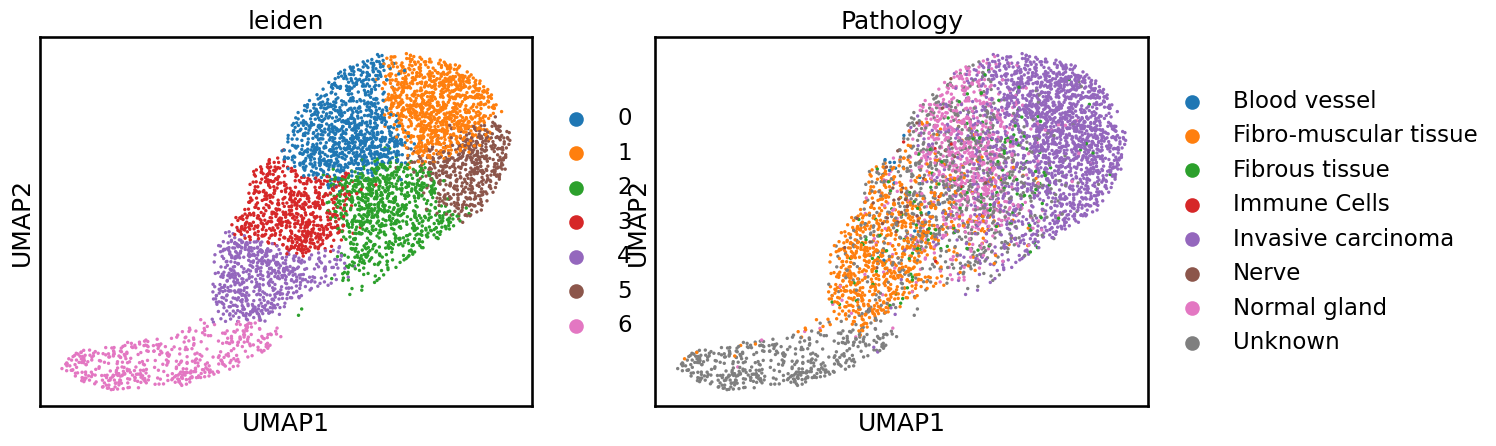

In [ ]:
# UMAP projection
sc.pp.neighbors(ref_embed_adata, use_rep="X")
sc.tl.umap(ref_embed_adata)
sc.tl.leiden(ref_embed_adata, resolution=0.7)
#sc.pl.umap(ref_embed_adata, color="leiden")
sc.pl.umap(ref_embed_adata, color=["leiden", "Pathology"])

### Visualize Leiden clusters in physical tissue space

Re-plots the same clusters using the spot's real 2D array coordinates rather than UMAP space, to check whether clusters correspond to spatially coherent tissue regions (a strong sign of biological meaningfulness).

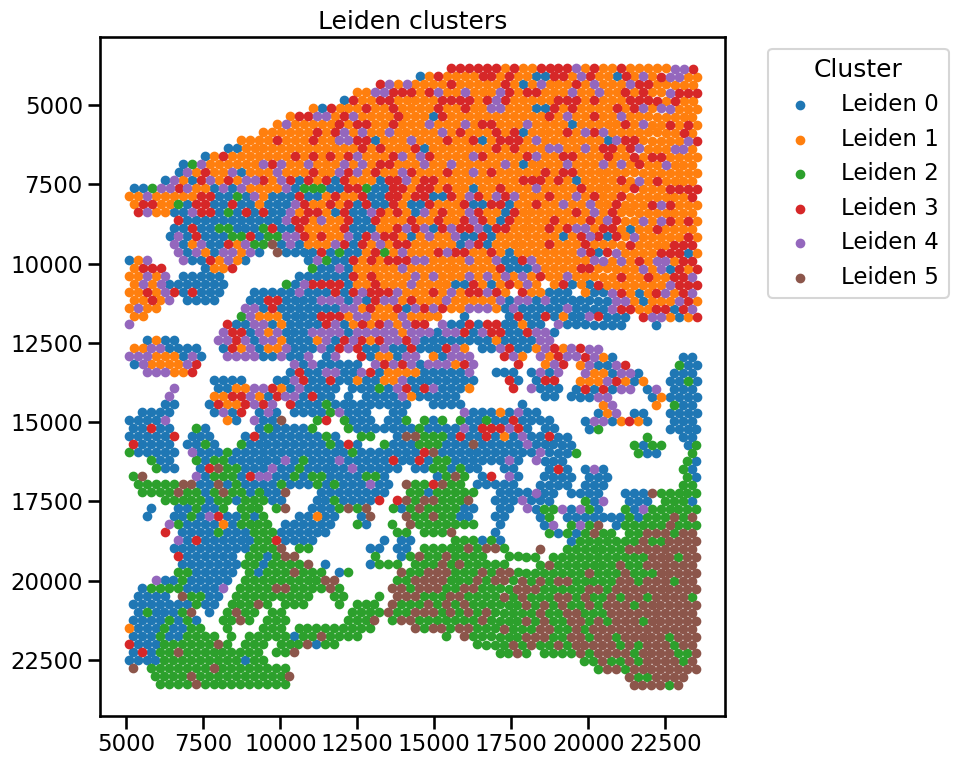

In [ ]:
# SPATIAL PLOT filtered
import numpy as np

ref_embed_adata.obsm['spatial'] = adata_filtered.obsm['spatial']
coords = ref_embed_adata.obsm["spatial"]
leiden_labels = ref_embed_adata.obs["leiden"].astype(str)
unique_labels = np.unique(leiden_labels)

plt.figure(figsize=(10,8))

for label in unique_labels:
    mask = leiden_labels == label
    plt.scatter(coords[mask, 0], coords[mask, 1], s=30, label=f"Leiden {label}")

plt.title("Leiden clusters")
plt.gca().invert_yaxis()
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
import scanpy as sc

# Suppose your AnnData object is `adata` and clusters are in adata.obs['louvain'] (or 'leiden')
print(adata.shape)  
print(adata.var_names[:10])  
print(ref_embed_adata.shape)  
print(ref_embed_adata.var_names[:10])  

(4992, 36945)
Index(['MIR1302-2HG', 'FAM138A', 'OR4F5', 'AL627309.1', 'AL627309.3',
       'AL627309.2', 'AL627309.5', 'AL627309.4', 'AP006222.2', 'AL732372.1'],
      dtype='object')
(4992, 512)
Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype='object')


In [ ]:
adata.obs_names[:5]

Index(['AAACAACGAATAGTTC-1', 'AAACAAGTATCTCCCA-1', 'AAACAATCTACTAGCA-1',
       'AAACACCAATAACTGC-1', 'AAACAGAGCGACTCCT-1'],
      dtype='object')

In [ ]:
ref_embed_adata.obs_names[:5]

Index(['AAACAACGAATAGTTC-1', 'AAACAAGTATCTCCCA-1', 'AAACAATCTACTAGCA-1',
       'AAACACCAATAACTGC-1', 'AAACAGAGCGACTCCT-1'],
      dtype='object')

### Differential expression per cluster

Normalizes and log-transforms raw counts, then runs a t-test-based rank-genes-groups analysis per Leiden cluster to identify marker genes, which are used to manually interpret/name each unsupervised cluster.

In [ ]:
#genes extraction filtered 
genes_adata = adata_filtered.copy()
genes_adata.obs['leiden'] = ref_embed_adata.obs['leiden']
# Step 1: Normalize total counts per cell
sc.pp.normalize_total(genes_adata, target_sum=1e4)

# Step 2: Logarithmize the data
sc.pp.log1p(genes_adata)  

In [ ]:
#obs check filtered
ref_embed_adata.obs

,Pathology,array_col,array_row,instance_id,cluster_0.2,cluster_0.4,cluster_0.6,cluster_0.8,cluster_1.0,cluster_1.2,cluster_1.4,cluster_1.6,cluster_1.8,cluster_2.0,cluster,leiden,cell_type_grouped
AAACAACGAATAGTTC-1,Unknown,16,0,0,2,4,6,7,9,9,12,12,15,15,4,6,Prostate luminal epithelial cells
AAACAAGTATCTCCCA-1,Normal gland,102,50,1,1,2,0,0,0,0,7,11,11,16,2,0,Immune cells
AAACAATCTACTAGCA-1,Unknown,43,3,2,2,4,6,6,7,7,8,9,14,14,4,6,Prostate secretory luminal epithelial cells
AAACACCAATAACTGC-1,Normal gland,19,59,3,0,2,0,2,0,0,2,3,2,4,2,0,Immune cells
AAACAGAGCGACTCCT-1,Invasive carcinoma,94,14,4,0,0,4,3,3,2,3,1,4,0,0,1,Prostate luminal epithelial cells
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTTTCACATCCAGG-1,Normal gland,42,58,4987,0,2,0,2,0,0,2,3,2,10,2,0,Immune cells
TTGTTTCATTAGTCTA-1,Fibro-muscular tissue,30,60,4988,1,1,3,0,5,4,4,2,1,1,1,3,Smooth muscle cells
TTGTTTCCATACAACT-1,Unknown,27,45,4989,1,1,3,0,5,4,4,2,1,1,1,3,Smooth muscle cells
TTGTTTGTATTACACG-1,Unknown,41,73,4990,1,1,2,4,4,3,1,0,3,2,1,4,Smooth muscle cells


In [ ]:
sc.tl.rank_genes_groups(genes_adata, groupby='leiden', method='t-test')  # or 'wilcoxon', 'logreg'

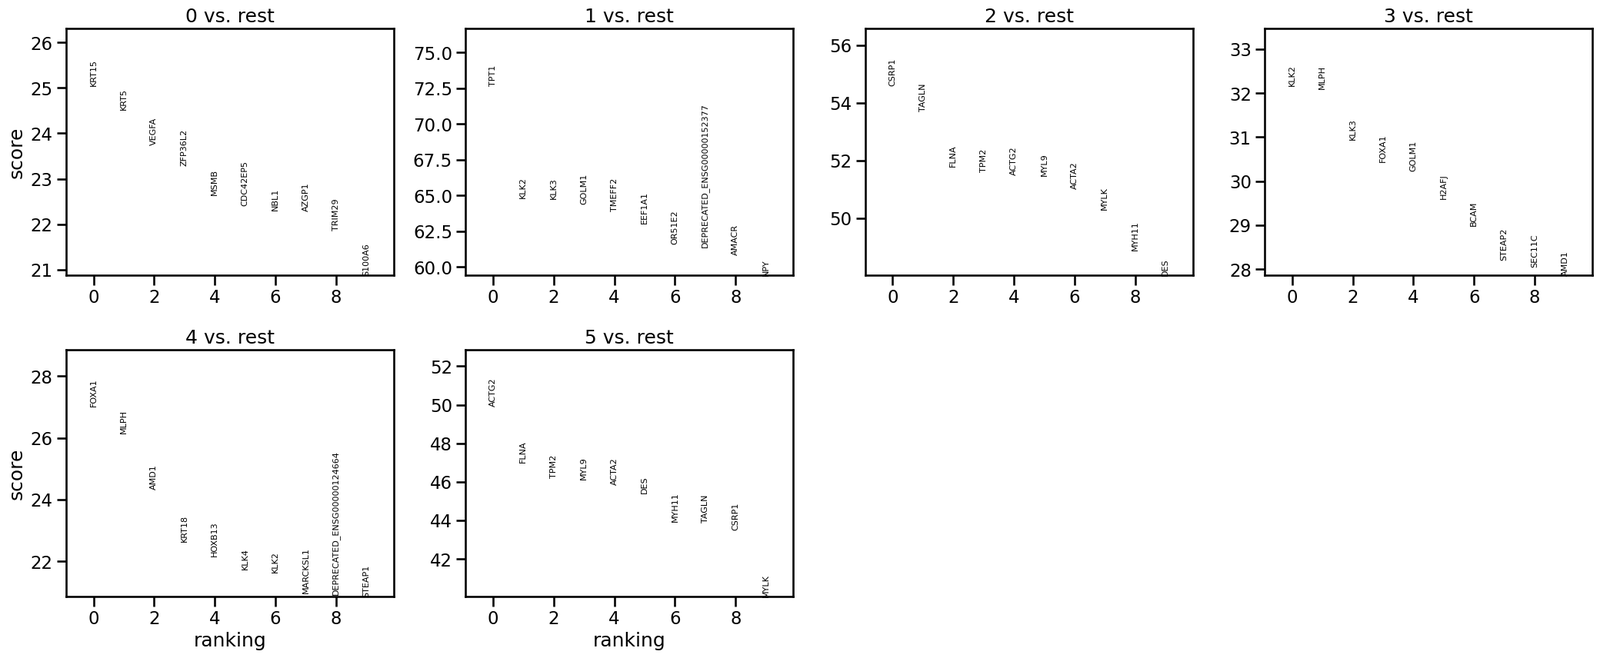

Cluster 0: ['KRT15', 'KRT5', 'VEGFA', 'ZFP36L2', 'MSMB', 'CDC42EP5', 'NBL1', 'AZGP1', 'TRIM29', 'S100A6']
Cluster 1: ['TPT1', 'KLK2', 'KLK3', 'GOLM1', 'TMEFF2', 'EEF1A1', 'OR51E2', 'DEPRECATED_ENSG00000152377', 'AMACR', 'NPY']
Cluster 2: ['CSRP1', 'TAGLN', 'FLNA', 'TPM2', 'ACTG2', 'MYL9', 'ACTA2', 'MYLK', 'MYH11', 'DES']
Cluster 3: ['KLK2', 'MLPH', 'KLK3', 'FOXA1', 'GOLM1', 'H2AFJ', 'BCAM', 'STEAP2', 'SEC11C', 'AMD1']
Cluster 4: ['FOXA1', 'MLPH', 'AMD1', 'KRT18', 'HOXB13', 'KLK4', 'KLK2', 'MARCKSL1', 'DEPRECATED_ENSG00000124664', 'STEAP1']
Cluster 5: ['ACTG2', 'FLNA', 'TPM2', 'MYL9', 'ACTA2', 'DES', 'MYH11', 'TAGLN', 'CSRP1', 'MYLK']


In [ ]:
# View top 10 genes per cluster
sc.pl.rank_genes_groups(genes_adata, n_genes=10, sharey=False)
# Extract cluster names
clusters = genes_adata.uns['rank_genes_groups']['names'].dtype.names
top_genes_per_cluster = {}

# Loop over clusters
for clust in clusters:
    top_genes = genes_adata.uns['rank_genes_groups']['names'][clust][:10]  # top 10 genes
    top_genes_per_cluster[clust] = list(top_genes)

# Print
for clust, genes in top_genes_per_cluster.items():
    print(f"Cluster {clust}: {genes}")

### Manually annotate clusters using marker genes

Based on the top marker genes above, clusters are grouped into coarse biological categories (e.g., cancerous luminal cells, smooth muscle, normal gland, fibrous tissue) for interpretability. Note: the cluster to label mapping is hardcoded per Leiden run and must be manually updated if resolution or random_state changes cluster numbering.

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# AnnData object is called 'ref_embed_adata'
# and already has leiden clusters in ref_embed_adata.obs['leiden']
# and spatial coordinates in ref_embed_adata.obsm['spatial']

# Create a new column for grouped cell types
grouped = pd.Series(index=ref_embed_adata.obs.index, dtype='object')

# Map original clusters to groups
luminal_clusters = ['1', '3']           
smooth_clusters  = ['2', '5']


grouped[ref_embed_adata.obs['leiden'].isin(luminal_clusters)] = 'Cancerous luminal cells'
grouped[ref_embed_adata.obs['leiden'].isin(smooth_clusters)]  = 'Smooth muscle cells'

# Fill remaining clusters with their original annotations (or keep as 'Leiden X')
remaining = {
    '0': 'Normal gland',
    '4': 'Normal gland',
}

for cl, label in remaining.items():
    grouped[ref_embed_adata.obs['leiden'] == cl] = label

# Assign any unassigned clusters (if any) as 'Other'
grouped = grouped.fillna('Other')

ref_embed_adata.obs['cell_type_grouped'] = grouped.astype('category')

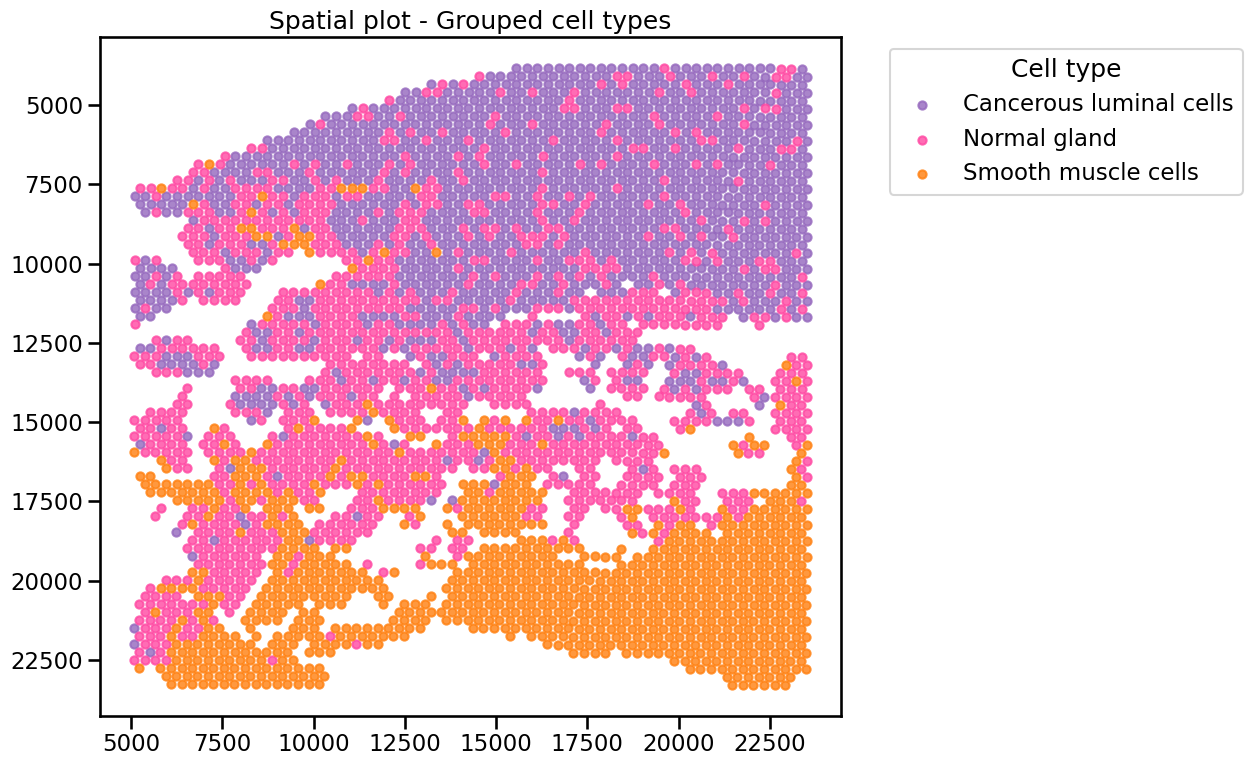

In [ ]:
# Scanpy's spatial plotting function (recommended for spatial data)

# Alternative: matplotlib scatter version, but with grouped colors
coords = ref_embed_adata.obsm["spatial"]
labels = ref_embed_adata.obs["cell_type_grouped"].astype(str)
unique_labels = np.unique(labels)
custom_palette = {                       
    'Smooth muscle cells': '#ff7f0e',                   
    'Cancerous luminal cells': '#9467bd',     
    'Fibrous tissue': 'green',             
    'Normal gland': '#ff47a2',              
    'Other': '#7f7f7f'                                  
}

plt.figure(figsize=(13, 8))

for label in unique_labels:
    mask = labels == label
    plt.scatter(
        coords[mask, 0],
        coords[mask, 1],
        s=35,
        label=label,
        alpha=0.8,
        color=custom_palette.get(label, '#7f7f7f') 
    )

plt.title("Spatial plot - Grouped cell types")
plt.gca().invert_yaxis()  
plt.legend(title="Cell type", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

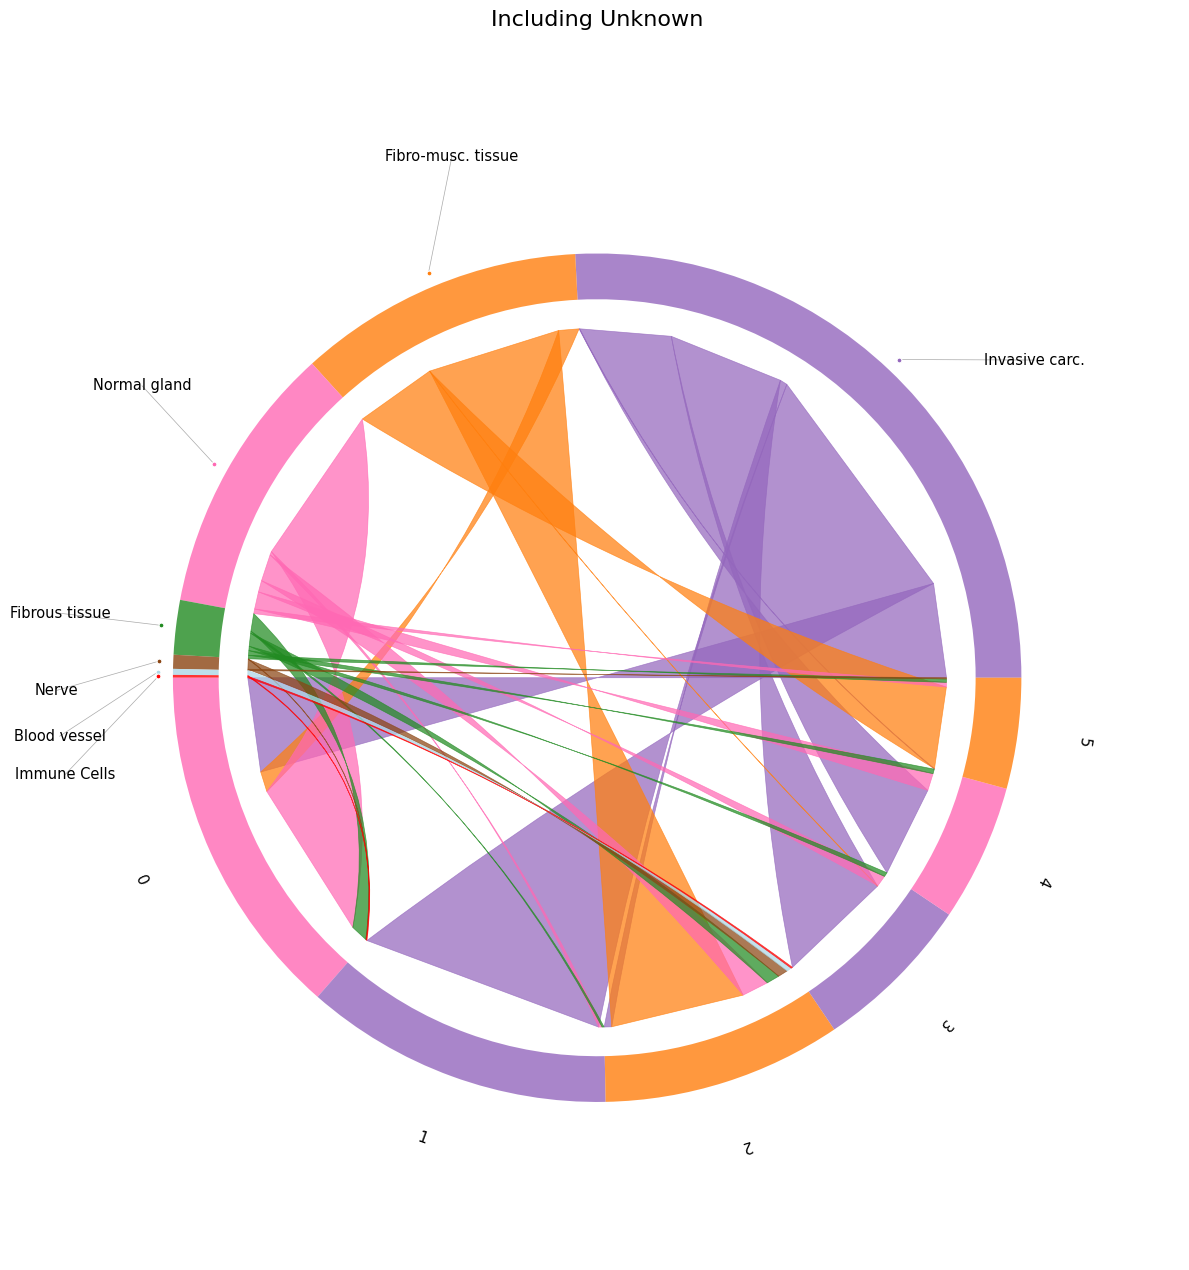

(<Figure size 1400x1400 with 1 Axes>,
 <Axes: title={'center': 'Including Unknown'}>)

In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, PathPatch
from matplotlib.path import Path
import pandas as pd

def polar2xy(r, theta_deg):
    theta = np.deg2rad(theta_deg)
    return r * np.array([np.cos(theta), np.sin(theta)])

def plot_pathology_vs_leiden_chord_improved(
    df,
    pathology_col="Pathology",
    leiden_col="leiden",
    min_count=1,                 
    filter_unknown=False,         
    sort_by='size',               
    figsize=(14, 14),
    chord_curvature=0.72,
    arc_thickness=0.11,
    gap=0.05,
    alpha=0.80,
    label_fontsize_path=12,
    label_fontsize_lei=11,
    title="Pathology vs Leiden Clusters (Including Unknown)"
):
    df = df[[pathology_col, leiden_col]].copy()
    if filter_unknown:
        df = df[df[pathology_col] != "Unknown"]

    crosstab = pd.crosstab(df[pathology_col], df[leiden_col])

    # Sort pathologies
    path_counts = crosstab.sum(axis=1)
    if sort_by == 'size':
        pathologies = path_counts.sort_values(ascending=False).index.tolist()
    else:
        pathologies = sorted(path_counts.index)

    leidens = sorted(crosstab.columns)  

    size_path = crosstab.sum(axis=1).reindex(pathologies).values
    size_lei  = crosstab.sum(axis=0).reindex(leidens).values
    total     = size_path.sum()

    if total == 0:
        raise ValueError("No data")

    angle_path = 180 * size_path / total
    angle_lei  = 180 * size_lei  / total

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_aspect("equal")
    ax.axis("off")

    # MANUAL COLOR DICTIONARIES 
    pathology_colors = {
        "Blood vessel":              "#add8e6",     
        "Fibro-muscular tissue":     "#ff7f0e",     
        "Fibrous tissue":            "#228b22",     
        "Immune Cells":              "#ff0000",    
        "Invasive carcinoma":        "#9467bd",      
        "Nerve":                     "#8b4513",     
        "Normal gland":              "#ff69b4",    
        "Unknown":                   "#c0c0c0",    
    }

    leiden_colors = {
        "0":   "#ff69b4",     
        "1":   "#9467bd",    
        "2":   "#ff7f0e",   
        "3":   "#9467bd",     
        "4":   "#ff69b4",    
        "5":   "#ff7f0e",  
        # add more if you have higher clusters
    }

    # Prepare color lists using dictionaries + fallback
    colors_path = []
    for label in pathologies:
        colors_path.append(pathology_colors.get(label, "#aaaaaa"))  
    colors_path = np.array(colors_path)

    colors_lei = []
    for cl in leidens:
        cl_str = str(cl)
        colors_lei.append(leiden_colors.get(cl_str, "#aaaaaa"))     
    colors_lei = np.array(colors_lei)

    # Pathology
    path_start = {}
    path_mid   = {}
    cum = 0.0
    for i, (label, ang) in enumerate(zip(pathologies, angle_path)):
        start = cum
        end   = cum + ang
        path_start[label] = (start, end)
        path_mid[label]   = (start + end) / 2

        wedge = Wedge((0,0), 1.02, start, end, width=arc_thickness,
                      facecolor=colors_path[i], edgecolor='none', alpha=alpha)
        ax.add_patch(wedge)

        cum = end

    # Pathology labels with leader lines 
    label_radius = 1.30          
    leader_color = '#555555'
    leader_lw = 0.5
    leader_alpha = 0.50

    for i, (label, mid_angle) in enumerate(zip(pathologies, path_mid.values())):
        x_inner, y_inner = polar2xy(1.0 + arc_thickness/2, mid_angle)
        
        offset = (i - (len(pathologies) - 1) / 2) * 3.5
        label_angle = mid_angle + offset
        x_outer, y_outer = polar2xy(label_radius, label_angle)
        
        ax.plot([x_inner, x_outer], [y_inner, y_outer],
                color=leader_color, lw=leader_lw, alpha=leader_alpha, zorder=5)
        
        ax.plot(x_inner, y_inner, 'o', ms=3.5, color=colors_path[i], 
                mec='white', mew=0.8, zorder=10)
        
        short_label = label.replace("carcinoma", "carc.").replace("Fibro-muscular", "Fibro-musc.")
        ax.text(x_outer, y_outer, short_label,
                ha='center', va='center',
                fontsize=10.5, fontweight='medium',
                rotation=0, zorder=15)

    # Lower: Leiden clusters
    lei_start = {}
    lei_mid   = {}
    cum = 180.0
    for i, (label, ang) in enumerate(zip(leidens, angle_lei)):
        start = cum
        end   = cum + ang
        lei_start[label] = (start, end)
        lei_mid[label]   = (start + end) / 2

        wedge = Wedge((0,0), 1.02, start, end, width=arc_thickness,
                      facecolor=colors_lei[i], edgecolor='none', alpha=alpha)
        ax.add_patch(wedge)

        angle_label = lei_mid[label]
        rot = angle_label - 90
        if 90 < angle_label < 270:
            rot += 180
            ha = 'right' if angle_label > 180 else 'left'
        else:
            ha = 'center'

        x, y = polar2xy(1.18, angle_label)
        ax.text(x, y, f"{int(label)}", ha=ha, va="center",
                fontsize=label_fontsize_lei, rotation=rot)

        cum = end

    # Chords 
    r_inner = 1 - arc_thickness - gap

    for i, path_label in enumerate(pathologies):
        start_s = path_start[path_label][0]
        color = colors_path[i]

        for j, lei_label in enumerate(leidens):
            flow = crosstab.loc[path_label, lei_label]
            if flow <= 0:
                continue

            portion_s = angle_path[i] * flow / size_path[i]
            s0 = start_s
            s1 = start_s + portion_s
            start_s = s1

            start_t = lei_start[lei_label][0]
            for prev in pathologies[:i]:
                prev_flow = crosstab.loc[prev, lei_label]
                if prev_flow > 0:
                    start_t += angle_lei[j] * prev_flow / size_lei[j]

            portion_t = angle_lei[j] * flow / size_lei[j]
            t0 = start_t
            t1 = start_t + portion_t

            p1 = polar2xy(r_inner, s0)
            p2 = polar2xy(r_inner, s1)
            p3 = polar2xy(r_inner, t0)
            p4 = polar2xy(r_inner, t1)

            mid13 = (p1 + p3) / 2 * chord_curvature
            mid24 = (p2 + p4) / 2 * chord_curvature

            verts = [p1, mid13, p3, p4, mid24, p2, p1]
            codes = [Path.MOVETO, Path.CURVE3, Path.CURVE3,
                     Path.LINETO, Path.CURVE3, Path.CURVE3, Path.CLOSEPOLY]

            patch = PathPatch(Path(verts, codes), facecolor=color,
                              edgecolor=color, lw=0.5, alpha=alpha*0.9)
            ax.add_patch(patch)

    ax.set_title(title, fontsize=16, pad=50)
    plt.tight_layout()
    ax.set_xlim(-1.4, 1.4)
    ax.set_ylim(-1.4, 1.4)
    ax.set_aspect('equal')
    plt.margins(0.25)
    plt.tight_layout(pad=3.0)
    plt.show()
    return fig, ax


# Run with your data 
plot_pathology_vs_leiden_chord_improved(ref_embed_adata.obs, min_count=1, filter_unknown=False, title="Including Unknown")

## Sensitivity to clustering resolution

Re-clusters cached embeddings at Leiden resolution 1.0 to check how stable the spatial domains are across resolutions.

In [ ]:
# Load the data
ref_embed_filtered = sc.read_h5ad("../tutorials/ref_embed_data_filtered.h5ad")

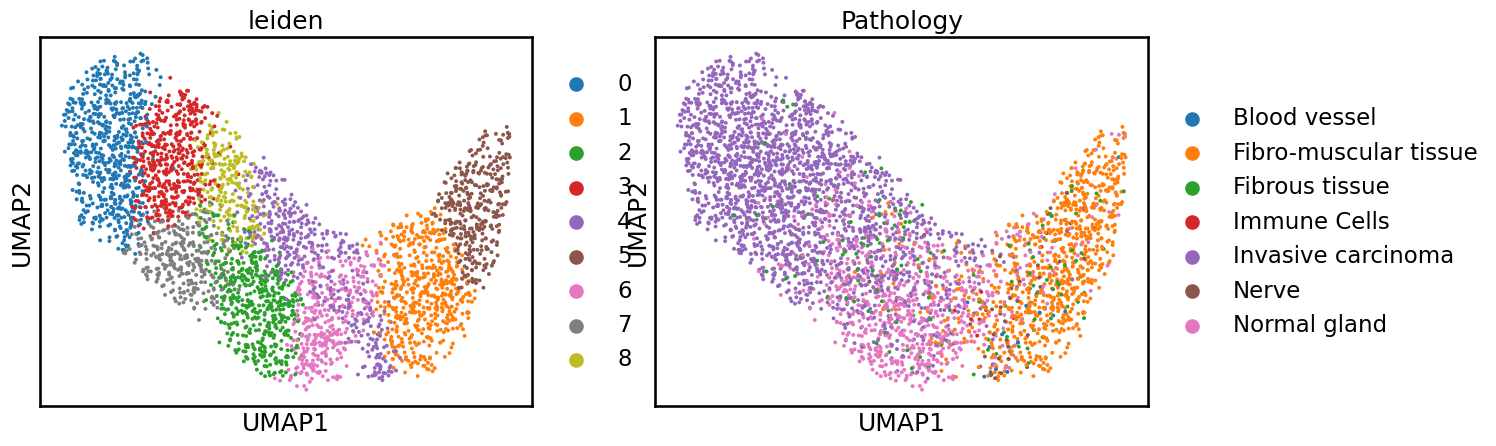

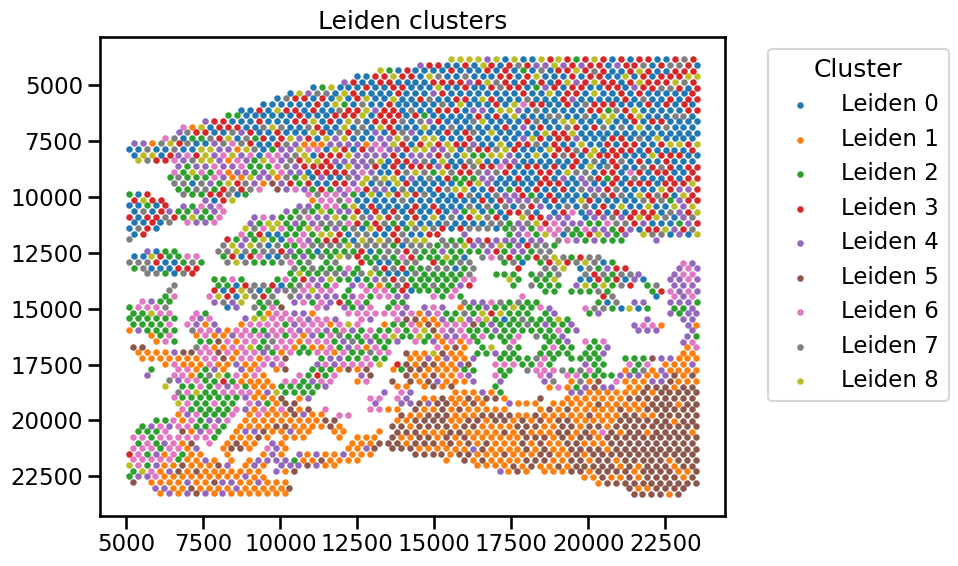

In [ ]:
# UMAP projection
sc.pp.neighbors(ref_embed_filtered, use_rep="X")
sc.tl.umap(ref_embed_filtered)
sc.tl.leiden(ref_embed_filtered, resolution=1)
#sc.pl.umap(ref_embed_filtered, color="leiden")
sc.pl.umap(ref_embed_filtered, color=["leiden", "Pathology"])

# SPATIAL PLOT non filtered
import matplotlib.pyplot as plt
import numpy as np

ref_embed_filtered.obsm['spatial'] = adata_filtered.obsm['spatial']
coords = ref_embed_filtered.obsm["spatial"]
leiden_labels = ref_embed_filtered.obs["leiden"].astype(str)
unique_labels = np.unique(leiden_labels)

plt.figure(figsize=(10,6))

for label in unique_labels:
    mask = leiden_labels == label
    plt.scatter(coords[mask, 0], coords[mask, 1], s=10, label=f"Leiden {label}")

plt.title("Leiden clusters")
plt.gca().invert_yaxis()
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Baseline: standard PCA pipeline

Normalisation → log1p → 2,000 highly variable genes → PCA → neighbours → Leiden. ARI and NMI against the pathologist annotation are computed for both the scGPT-spatial clusters and this baseline.

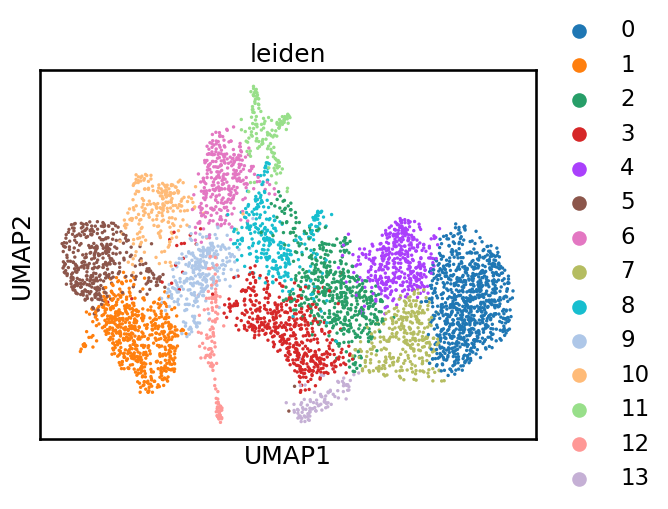

In [ ]:
adata_baseline = adata.copy()

sc.pp.normalize_total(adata_baseline)
sc.pp.log1p(adata_baseline)
sc.pp.highly_variable_genes(adata_baseline, n_top_genes=2000)
adata_baseline = adata_baseline[:, adata_baseline.var.highly_variable]

sc.pp.pca(adata_baseline)
sc.pp.neighbors(adata_baseline)
sc.tl.umap(adata_baseline)
sc.tl.leiden(adata_baseline)

sc.pl.umap(adata_baseline, color="leiden")


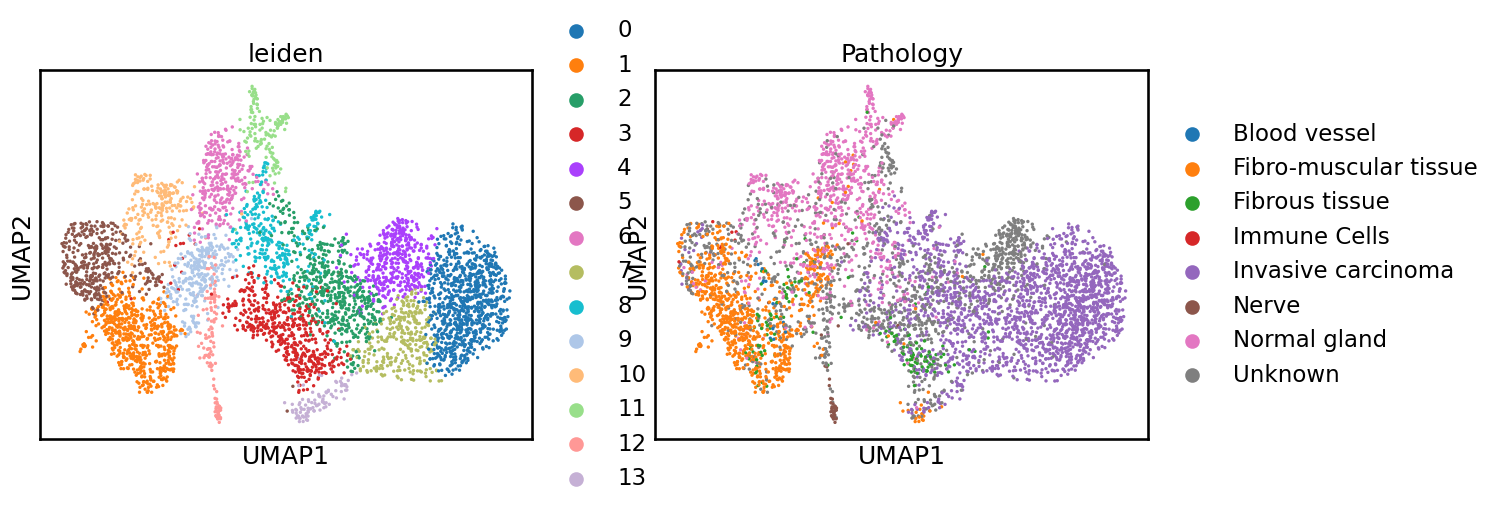

In [ ]:
sc.pl.umap(adata_baseline, color=["leiden", "Pathology"])

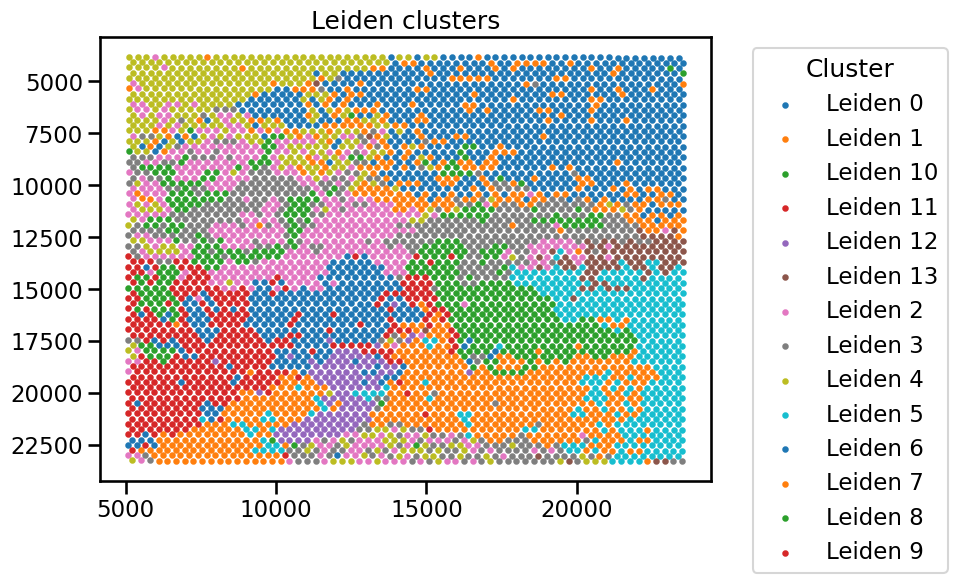

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

adata_baseline.obsm['spatial'] = adata.obsm['spatial']
coords = adata_baseline.obsm["spatial"]
leiden_labels = adata_baseline.obs["leiden"].astype(str)
unique_labels = np.unique(leiden_labels)

plt.figure(figsize=(10,6))

for label in unique_labels:
    mask = leiden_labels == label
    plt.scatter(coords[mask, 0], coords[mask, 1], s=10, label=f"Leiden {label}")

plt.title("Leiden clusters")
plt.gca().invert_yaxis()
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari_scgpt = adjusted_rand_score(ref_embed_adata.obs["Pathology"], ref_embed_adata.obs["leiden"])
ari_baseline = adjusted_rand_score(adata_baseline.obs["Pathology"], adata_baseline.obs["leiden"])

nmi_scgpt = normalized_mutual_info_score(ref_embed_adata.obs["Pathology"], ref_embed_adata.obs["leiden"])
nmi_baseline = normalized_mutual_info_score(adata_baseline.obs["Pathology"], adata_baseline.obs["leiden"])

print("ARI scGPT:", ari_scgpt)
print("ARI baseline:", ari_baseline)
print("NMI scGPT:", nmi_scgpt)
print("NMI baseline:", nmi_baseline)

ARI scGPT: 0.24619689366954325
ARI baseline: 0.2515240457044724
NMI scGPT: 0.3311183506974627
NMI baseline: 0.37726759741244675


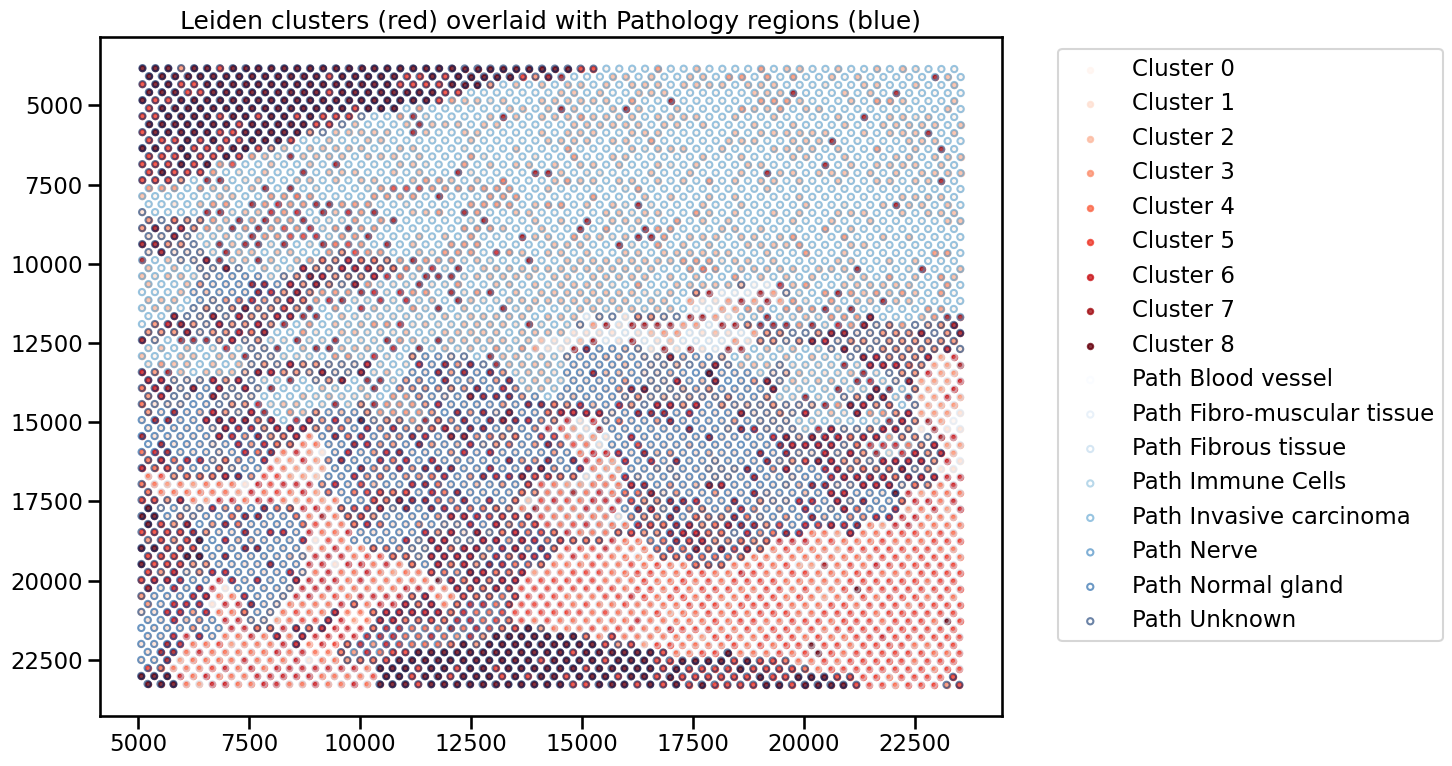

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import Reds, Blues

coords = ref_embed_adata.obsm["spatial"]
leiden_labels = ref_embed_adata.obs["leiden"].astype(str)
path_labels = ref_embed_adata.obs["Pathology"].astype(str)

plt.figure(figsize=(15,8))

# Generate shades of red for clusters
unique_clusters = np.unique(leiden_labels)
n_clusters = len(unique_clusters)
cluster_colors = [Reds(i / max(1, n_clusters-1)) for i in range(n_clusters)]
cluster_dict = dict(zip(unique_clusters, cluster_colors))

# Generate shades of blue for pathology 
unique_path = np.unique(path_labels)
n_path = len(unique_path)
path_colors = [Blues(i / max(1, n_path-1)) for i in range(n_path)]
path_dict = dict(zip(unique_path, path_colors))

# Plot clusters (filled red dots)
for cluster in unique_clusters:
    mask = leiden_labels == cluster
    plt.scatter(
        coords[mask,0], coords[mask,1],
        s=15,
        color=cluster_dict[cluster],
        label=f"Cluster {cluster}",
        alpha=0.8
    )

# Overlay pathology regions (blue outlines)
for label in unique_path:
    mask = path_labels == label
    plt.scatter(
        coords[mask,0], coords[mask,1],
        facecolors='none',
        edgecolors=path_dict[label],
        s=20,
        linewidths=1.5,
        label=f"Path {label}",
        alpha=0.6
    )

plt.gca().invert_yaxis()
plt.title("Leiden clusters (red) overlaid with Pathology regions (blue)")

# Clean legend 
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), bbox_to_anchor=(1.05,1))
plt.tight_layout()
plt.show()
